In [1]:
from pathlib import Path
import calendar

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# 数据文件路径
DATA_FILE = Path(r"C:\Users\admin\US1IATM0004.csv")
# 只读取需要的列
columns = ["DATE", "PRCP", "DP01", "DP10", "DP1X", "EMXP"]

df = pd.read_csv(DATA_FILE, usecols=columns)

# 显示数据规模和前五行
print("原始数据形状：", df.shape)
display(df.head())

原始数据形状： (87, 6)


,DATE,DP01,DP10,DP1X,EMXP,PRCP
0,2019-07,6,6,0,22.6,84.6
1,2019-08,8,6,2,46.0,121.1
2,2019-09,14,14,2,31.0,179.7
3,2019-10,11,11,2,54.6,182.2
4,2019-11,7,7,0,9.1,43.6


In [ ]:
#4.1 数据清洗

In [2]:
# DATE 形如 2019-07，转换成每月第一天
df["DATE"] = pd.to_datetime(
    df["DATE"],
    format="%Y-%m",
    errors="coerce",
)

# 统一把数值列转换成数值类型
for col in ["PRCP", "DP01", "DP10", "DP1X", "EMXP"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 记录清洗前信息
raw_rows = len(df)
missing_date = df["DATE"].isna().sum()
missing_prcp = df["PRCP"].isna().sum()
duplicate_months = df["DATE"].duplicated().sum()

# 删除日期或 PRCP 缺失的记录
df = df.dropna(subset=["DATE", "PRCP"])

# 删除重复月份
df = df.drop_duplicates(subset=["DATE"], keep="last")

# 找出不合理记录
invalid = (
    (df["PRCP"] < 0)
    | (df["EMXP"] < 0)
    | (df["EMXP"] > df["PRCP"])
    | (df["DP10"] > df["DP01"])
    | (df["DP1X"] > df["DP10"])
    | (df["DP01"] > df["DATE"].dt.days_in_month)
)

# 保存异常值数量
invalid_count = int(invalid.sum())

# 删除异常记录并按时间排序
df = df.loc[~invalid].sort_values("DATE").reset_index(drop=True)

# 检查月份是否连续
expected_months = pd.date_range(
    start=df["DATE"].min(),
    end=df["DATE"].max(),
    freq="MS",
)
missing_months = expected_months.difference(df["DATE"])
completeness = len(df) / len(expected_months)

# 用一张表展示清洗结果
cleaning_report = pd.DataFrame(
    {
        "项目": [
            "原始行数",
            "DATE 缺失",
            "PRCP 缺失",
            "重复月份",
            "异常记录",
            "清洗后行数",
            "起始月份",
            "结束月份",
            "缺失月份数",
            "数据完整率",
        ],
        "结果": [
            raw_rows,
            missing_date,
            missing_prcp,
            duplicate_months,
            invalid_count,
            len(df),
            df["DATE"].min().strftime("%Y-%m"),
            df["DATE"].max().strftime("%Y-%m"),
            len(missing_months),
            f"{completeness:.2%}",
        ],
    }
)

display(cleaning_report)
display(df.head())

,项目,结果
0,原始行数,87
1,DATE 缺失,0
2,PRCP 缺失,0
3,重复月份,0
4,异常记录,0
5,清洗后行数,87
6,起始月份,2019-07
7,结束月份,2026-09
8,缺失月份数,0
9,数据完整率,100.00%


,DATE,DP01,DP10,DP1X,EMXP,PRCP
0,2019-07-01,6,6,0,22.6,84.6
1,2019-08-01,8,6,2,46.0,121.1
2,2019-09-01,14,14,2,31.0,179.7
3,2019-10-01,11,11,2,54.6,182.2
4,2019-11-01,7,7,0,9.1,43.6


In [ ]:
#4.2 月降水量时间序列

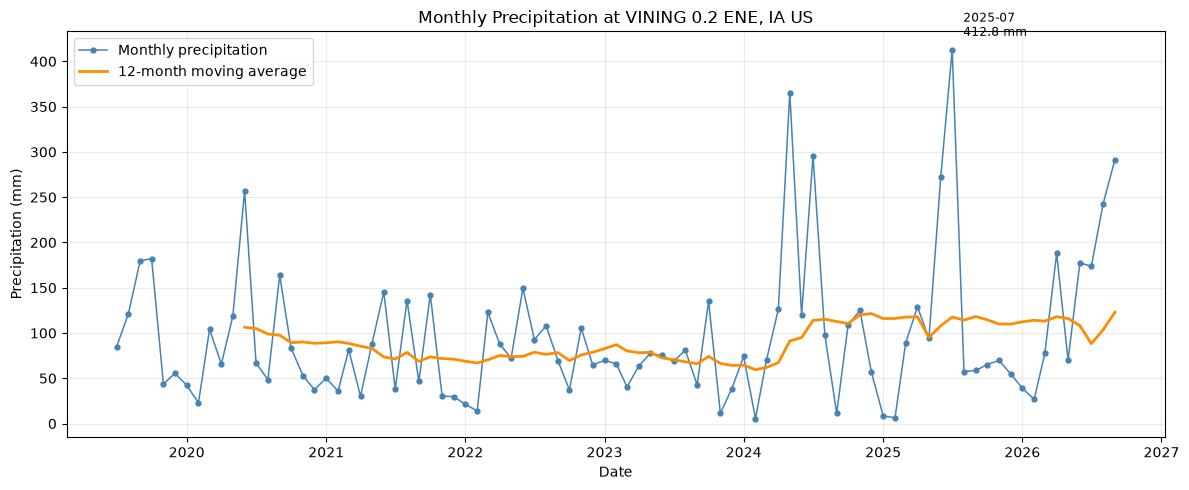

In [3]:
# 设置日期索引
monthly = df.set_index("DATE")["PRCP"]

# 12 个月移动平均
rolling_12 = monthly.rolling(12).mean()

# 创建图形
fig, ax = plt.subplots(figsize=(12, 5))

# 原始月降水量
ax.plot(
    monthly.index,
    monthly,
    color="steelblue",
    marker="o",
    markersize=3.5,
    linewidth=1.1,
    label="Monthly precipitation",
)

# 移动平均线
ax.plot(
    rolling_12.index,
    rolling_12,
    color="darkorange",
    linewidth=2,
    label="12-month moving average",
)

# 标出最大降水月份
max_row = df.loc[df["PRCP"].idxmax()]
ax.annotate(
    f"{max_row['DATE']:%Y-%m}\n{max_row['PRCP']:.1f} mm",
    xy=(max_row["DATE"], max_row["PRCP"]),
    xytext=(8, 10),
    textcoords="offset points",
    fontsize=8.5,
)

# 设置图形文字
ax.set_title("Monthly Precipitation at VINING 0.2 ENE, IA US")
ax.set_xlabel("Date")
ax.set_ylabel("Precipitation (mm)")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()

plt.show()

In [ ]:
#4.3.1 描述统计与季节性

4.3 检查 1：描述统计


,count,mean,std,min,25%,50%,75%,max
PRCP,87.0,96.11954,77.836544,5.6,45.05,72.1,121.9,412.8


变异系数 CV = 0.810
偏度 = 1.885

4.3 检查 2：完整性
有效月份 87 / 应有月份 87
完整率 = 100.00%

4.3 检查 3：月份季节性


,mean,median,std,count
MONTH,,,,
1,43.67,42.40,23.85,7
2,25.33,22.90,21.01,7
3,83.67,81.50,25.99,7
4,98.64,88.00,52.82,7
5,126.50,88.10,106.63,7
6,171.03,149.50,71.42,7
7,154.16,88.65,133.32,8
8,111.59,102.90,60.88,8
9,107.96,64.05,95.06,8


最湿月份：6 月，平均 171.03 mm
最干月份：2 月，平均 25.33 mm


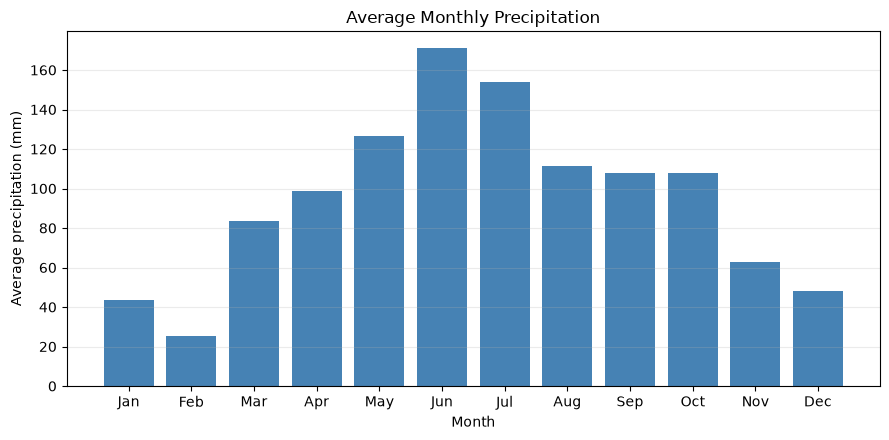

In [4]:
# 检查 1：描述统计
summary = df["PRCP"].describe()
cv = df["PRCP"].std() / df["PRCP"].mean()
skewness = df["PRCP"].skew()

print("4.3 检查 1：描述统计")
display(summary.to_frame().T)
print(f"变异系数 CV = {cv:.3f}")
print(f"偏度 = {skewness:.3f}")

# 检查 2：完整性
print("\n4.3 检查 2：完整性")
print(f"有效月份 {len(df)} / 应有月份 {len(expected_months)}")
print(f"完整率 = {completeness:.2%}")

# 检查 3：月份季节性
df["MONTH"] = df["DATE"].dt.month

monthly_climatology = (
    df.groupby("MONTH")["PRCP"]
      .agg(["mean", "median", "std", "count"])
)

print("\n4.3 检查 3：月份季节性")
display(monthly_climatology.round(2))

wettest_month = monthly_climatology["mean"].idxmax()
driest_month = monthly_climatology["mean"].idxmin()

print(
    f"最湿月份：{wettest_month} 月，"
    f"平均 {monthly_climatology.loc[wettest_month, 'mean']:.2f} mm"
)
print(
    f"最干月份：{driest_month} 月，"
    f"平均 {monthly_climatology.loc[driest_month, 'mean']:.2f} mm"
)

# 绘制季节柱状图
month_labels = [
    calendar.month_abbr[m]
    for m in monthly_climatology.index
]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(month_labels, monthly_climatology["mean"], color="steelblue")
ax.set_title("Average Monthly Precipitation")
ax.set_xlabel("Month")
ax.set_ylabel("Average precipitation (mm)")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()

plt.show()

In [ ]:
#4.3.2 趋势、相关性和极端值

In [6]:
# 检查 4：线性趋势
years = (df["DATE"] - df["DATE"].min()).dt.days / 365.25

slope, intercept = np.polyfit(years, df["PRCP"], 1)
time_corr = np.corrcoef(years, df["PRCP"])[0, 1]
r_squared = time_corr**2

print("4.3 检查 4：长期趋势")
print(f"每年变化：{slope:.2f} mm")
print(f"每十年变化：{slope * 10:.2f} mm")
print(f"R² = {r_squared:.3f}")
print(f"时间相关系数 = {time_corr:.3f}")

# 检查 5：PRCP 与降水日数的相关性
corr_table = (
    df[["PRCP", "DP01", "DP10", "DP1X", "EMXP"]]
    .corr()["PRCP"]
    .drop("PRCP")
    .to_frame("与 PRCP 的相关系数")
)

print("\n4.3 检查 5：相关性")
display(corr_table.round(3))

4.3 检查 4：长期趋势
每年变化：7.29 mm
每十年变化：72.87 mm
R² = 0.039
时间相关系数 = 0.197

4.3 检查 5：相关性


,与 PRCP 的相关系数
DP01,0.768
DP10,0.787
DP1X,0.870
EMXP,0.815
